# Handwritten digit prediction using multi-input output ANN model

In [1]:
# importing libraries 
import tensorflow 
from tensorflow import keras 
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense,Flatten

In [2]:
# taking the mnist dataset from keras
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


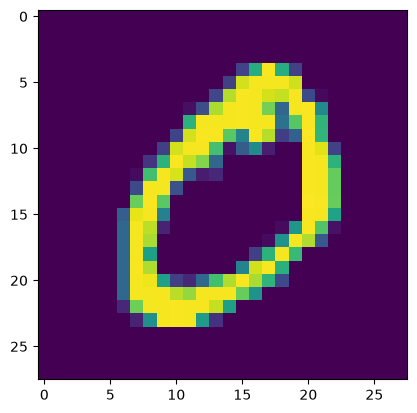

In [8]:
# demonstrating a number in image 
import matplotlib.pyplot as plt 
plt.imshow(X_train[1])

In [9]:
# converging all pixel values between the range from 0 to 1 
X_train = X_train/255 
X_test = X_test/255 
X_train

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [18]:
# fixing the model architecture 
model = Sequential() 
model.add(Flatten(input_shape=(28,28))) 
model.add(Dense(128,activation='relu')) 
model.add(Dense(10,activation='softmax'))

In [19]:
# model summary 
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# compiling the model
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy']) 

In [39]:
history=model.fit(X_train,y_train,epochs=4,validation_split=0.4)

Epoch 1/4
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9995 - loss: 0.0025 - val_accuracy: 0.9877 - val_loss: 0.1053
Epoch 2/4
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9986 - loss: 0.0047 - val_accuracy: 0.9879 - val_loss: 0.0991
Epoch 3/4
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9997 - loss: 7.8979e-04 - val_accuracy: 0.9892 - val_loss: 0.0924
Epoch 4/4
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 1.0000 - loss: 7.3029e-05 - val_accuracy: 0.9898 - val_loss: 0.0894


In [40]:
# predicting and calculating model accuracy 
y_prob = model.predict(X_test) 
y_pred = y_prob.argmax(axis=1) 
from sklearn.metrics import accuracy_score 
accuracy_score(y_test,y_pred)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


0.979

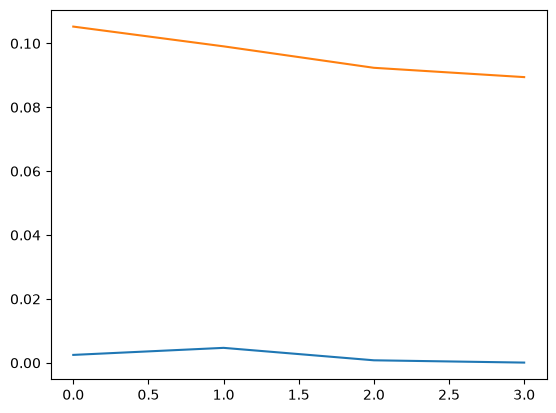

In [41]:
# plotting loss 
import matplotlib.pyplot as plt 
plt.plot(history.history['loss']) 
plt.plot(history.history['val_loss'])

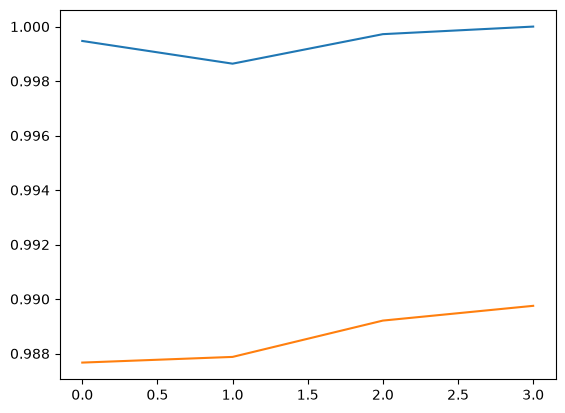

In [42]:
# plotting accuracies 
plt.plot(history.history['accuracy']) 
plt.plot(history.history['val_accuracy'])

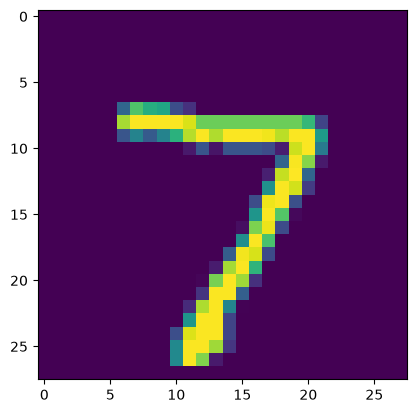

In [46]:
# plotting a test digit 
plt.imshow(X_test[0])

In [47]:
# testing the model in x_test data 
model.predict(X_test[0].reshape(1,28,28)).argmax()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


np.int64(7)